In [1]:
import pandas as pd
import numpy as np

## 1. Business case & Data Collection

## 2.Data Understanding

### 2.1 Exploratorio Inicial

In [ ]:
#Cargo el dataframe desde un archivo CSV
df = pd.read_csv("../data/steel-faults.csv", sep=",")

In [3]:
#Obtengo el numero de filas y columnas de la tabla (utilizo una sola tabla)
print("Número de filas y columnas:", df.shape)

Número de filas y columnas: (1941, 34)


In [4]:
#Saco la información del dataframe (tipo de datos, cantidad de valores no nulos, etc.)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1941 entries, 0 to 1940
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   X_Minimum              1941 non-null   int64  
 1   X_Maximum              1941 non-null   int64  
 2   Y_Minimum              1941 non-null   int64  
 3   Y_Maximum              1941 non-null   int64  
 4   Pixels_Areas           1941 non-null   int64  
 5   X_Perimeter            1941 non-null   int64  
 6   Y_Perimeter            1941 non-null   int64  
 7   Sum_of_Luminosity      1941 non-null   int64  
 8   Minimum_of_Luminosity  1941 non-null   int64  
 9   Maximum_of_Luminosity  1941 non-null   int64  
 10  Length_of_Conveyer     1941 non-null   int64  
 11  TypeOfSteel_A300       1941 non-null   int64  
 12  TypeOfSteel_A400       1941 non-null   int64  
 13  Steel_Plate_Thickness  1941 non-null   int64  
 14  Edges_Index            1941 non-null   float64
 15  Empty_Index    

In [5]:
#Muestro los primeros registros del dataframe
df.head()

,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,...,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


In [6]:
#Muestro los últimos registros del dataframe
df.tail()

,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
1936,249,277,325780,325796,273,54,22,35033,119,141,...,-0.4286,0.0026,0.7254,0,0,0,0,0,0,1
1937,144,175,340581,340598,287,44,24,34599,112,133,...,-0.4516,-0.0582,0.8173,0,0,0,0,0,0,1
1938,145,174,386779,386794,292,40,22,37572,120,140,...,-0.4828,0.0052,0.7079,0,0,0,0,0,0,1
1939,137,170,422497,422528,419,97,47,52715,117,140,...,-0.0606,-0.0171,0.9919,0,0,0,0,0,0,1
1940,1261,1281,87951,87967,103,26,22,11682,101,133,...,-0.2000,-0.1139,0.5296,0,0,0,0,0,0,1


### 2.2 Tabla de Variables

In [7]:
#Defino las listas de vbles en fn de su naturaleza
coordenadas = ['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum']
magnitud = ['Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index']
intensidad = ['Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Luminosity_Index']
maq_mat = ['Length_of_Conveyer', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness']
forma = ['Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'Orientation_Index', 'SigmoidOfAreas']
defecto = ['Pastry', 'Z_Scratch', 'K_Scatch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']

In [8]:
#importo las funciones del archivo funciones.py
import sys
import os
sys.path.append(os.path.abspath('../'))
from utils.funciones import asignar_naturaleza, asignar_definicion

In [9]:
#Construyo el inventario
tabla_vbles = pd.DataFrame({
    'Variable': df.columns,
    'Tipo de Dato': df.dtypes.values,
    'Naturaleza': [asignar_naturaleza(c, coordenadas, magnitud, intensidad, maq_mat, forma, defecto) for c in df.columns],
    'Descripción': [asignar_definicion(c, coordenadas, magnitud, intensidad, maq_mat, forma, defecto) for c in df.columns]
})

tabla_vbles.sort_values(by='Naturaleza').reset_index(drop=True)

,Variable,Tipo de Dato,Naturaleza,Descripción
0,TypeOfSteel_A300,int64,Características de la Maquinaria y Material,Parámetros de configuración de la maquinaria y...
1,Steel_Plate_Thickness,int64,Características de la Maquinaria y Material,Parámetros de configuración de la maquinaria y...
2,TypeOfSteel_A400,int64,Características de la Maquinaria y Material,Parámetros de configuración de la maquinaria y...
3,Length_of_Conveyer,int64,Características de la Maquinaria y Material,Parámetros de configuración de la maquinaria y...
4,X_Minimum,int64,Coordenadas y Ubicación Espacial (Geometría de...,"Estas variables delimitan el ""cuadro contenedo..."
5,X_Maximum,int64,Coordenadas y Ubicación Espacial (Geometría de...,"Estas variables delimitan el ""cuadro contenedo..."
6,Y_Maximum,int64,Coordenadas y Ubicación Espacial (Geometría de...,"Estas variables delimitan el ""cuadro contenedo..."
7,Y_Minimum,int64,Coordenadas y Ubicación Espacial (Geometría de...,"Estas variables delimitan el ""cuadro contenedo..."
8,Sum_of_Luminosity,int64,Intensidad y Luminosidad (Análisis Óptico),Indican cómo refleja la luz el defecto. Las fa...
9,Minimum_of_Luminosity,int64,Intensidad y Luminosidad (Análisis Óptico),Indican cómo refleja la luz el defecto. Las fa...


## 3.Data Cleaning

In [10]:
#Como ya vi en la info() del df que no hay nulos, compruebo ahora si tengo duplicados por si acaso
#importo la funcion
from utils.funciones import duplicados
duplicados(df)

El número total de elementos duplicados es de: 0


In [11]:
#Compruebo si tengo outliers
from utils.funciones import detectar_outliers
columnas_a_analizar = coordenadas + magnitud + intensidad + maq_mat + forma
tabla_outliers = detectar_outliers(df, columnas_a_analizar)
print(tabla_outliers)

                 Variable     Mínimo     Q1 (25%)  Mediana (50%)  \
0               X_Minimum     0.0000      51.0000   4.350000e+02   
1               X_Maximum     4.0000     192.0000   4.670000e+02   
2               Y_Minimum  6712.0000  471253.0000   1.204128e+06   
3               Y_Maximum  6724.0000  471281.0000   1.204136e+06   
4            Pixels_Areas     2.0000      84.0000   1.740000e+02   
5             X_Perimeter     2.0000      15.0000   2.600000e+01   
6             Y_Perimeter     1.0000      13.0000   2.500000e+01   
7              LogOfAreas     0.3010       1.9243   2.240600e+00   
8             Log_X_Index     0.3010       1.0000   1.176100e+00   
9             Log_Y_Index     0.0000       1.0792   1.322200e+00   
10      Sum_of_Luminosity   250.0000    9522.0000   1.920200e+04   
11  Minimum_of_Luminosity     0.0000      63.0000   9.000000e+01   
12  Maximum_of_Luminosity    37.0000     124.0000   1.270000e+02   
13       Luminosity_Index    -0.9989      -0.195

In [12]:
#Creo una columna categórica para el tipo de acero
from utils.funciones import asignar_tipo_acero
df['Tipo_Acero'] = df.apply(asignar_tipo_acero, axis=1)
print(df['Tipo_Acero'].value_counts())
df[['TypeOfSteel_A300', 'TypeOfSteel_A400', 'Tipo_Acero']].head()

Tipo_Acero
A400    1164
A300     777
Name: count, dtype: int64


,TypeOfSteel_A300,TypeOfSteel_A400,Tipo_Acero
0,1,0,A300
1,1,0,A300
2,1,0,A300
3,0,1,A400
4,0,1,A400


In [13]:
#creo una columna categorica para el tipo de defecto
from utils.funciones import asignar_tipo_defecto
df['Tipo_Defecto'] = df.apply(lambda fila: asignar_tipo_defecto(fila, defecto), axis=1)
print(df['Tipo_Defecto'].value_counts())
df[defecto + ['Tipo_Defecto']].head()

Tipo_Defecto
Other_Faults    673
Bumps           402
K_Scatch        391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55
Name: count, dtype: int64


,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults,Tipo_Defecto
0,1,0,0,0,0,0,0,Pastry
1,1,0,0,0,0,0,0,Pastry
2,1,0,0,0,0,0,0,Pastry
3,1,0,0,0,0,0,0,Pastry
4,1,0,0,0,0,0,0,Pastry


In [14]:
#Creo una tabla Tipo de Acero vs Tipo de Defecto
pd.crosstab(df['Tipo_Acero'], df['Tipo_Defecto'], margins=True)

Tipo_Defecto,Bumps,Dirtiness,K_Scatch,Other_Faults,Pastry,Stains,Z_Scratch,All
Tipo_Acero,,,,,,,,
A300,279,9,1,266,49,1,172,777
A400,123,46,390,407,109,71,18,1164
All,402,55,391,673,158,72,190,1941


De acuerdo a la tabla anterior:  
* El acero A300 parece vulnerable a las deformaciones físicas por impacto (Bumps) y a las ralladuras superficiales finas (Z_Scratch).  
* Las rayas severas (K_Scatch) longitudinales están ligadas de forma casi exclusiva al acero A400.
* Las manchas (Stains) y la suciedad (Dirtiness) penalizan más al A400, ya que, concentra 71 de las 72 manchas químicas (Stains) y 46 de las 55 impurezas (Dirtiness).

In [ ]:
#Creo una tabla Espesor vs Tipo de Defecto
from utils.funciones import agrupar_espesores
df['Rango_Espesor'] = df['Steel_Plate_Thickness'].apply(agrupar_espesores)
pd.crosstab(df['Rango_Espesor'], df['Tipo_Defecto'], margins=True)

Tipo_Defecto,Bumps,Dirtiness,K_Scatch,Other_Faults,Pastry,Stains,Z_Scratch,All
Rango_Espesor,,,,,,,,
1 Fino (<= 60mm),152,13,390,226,52,71,8,912
2 Medio (61mm - 150mm),222,42,1,305,90,1,172,833
3 Grueso / Industrial (> 150mm),28,0,0,142,16,0,10,196
All,402,55,391,673,158,72,190,1941


De acuerdo a la tabla anterior parece que:   
* En los espesores más finos es más probable tener rayas superficiales.  
* Para espesores medios es más fácil que se produzcan abolladuras (bumps).  
* Y en espesores gruesos parece que la visión artificial no es capaz de identificar la mayoría de los defectos, asignándolos a 'Other_Faults'.

## 4.Analysis

### 4.1 Análisis univariante

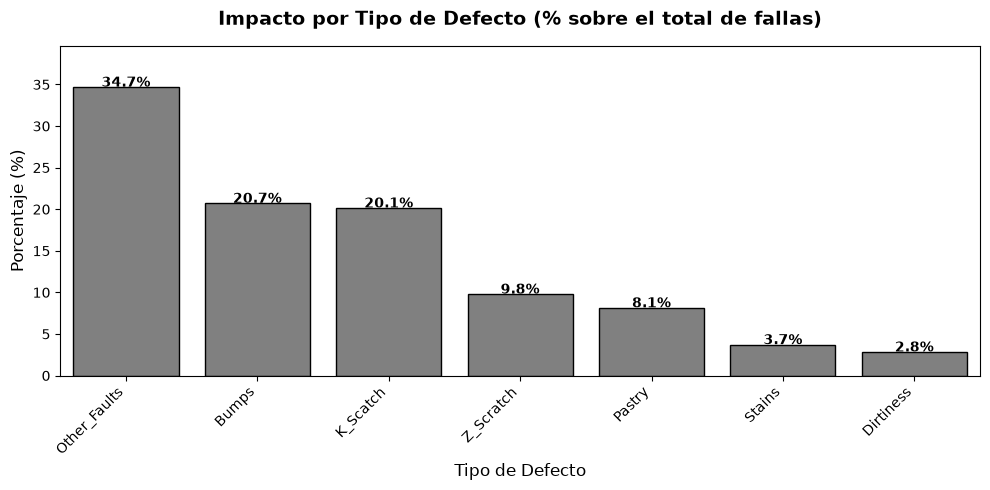

In [ ]:
# Importamos las nuevas funciones desde tu carpeta utils
from utils.funciones import plot_porcentaje_defectos

plot_porcentaje_defectos(df)

#### CONCLUSIONES  
* El defecto más frecuente con diferencia es 'Other_Faults' con un 34.7%. Más de una de cada tres defectos detectados en planta cae en esta categoría genérica. El sistema automático de visión artificial de la fábrica no es capaz de clasificar con precisión estas imperfecciones. Dejar un volumen tan alto (casi el 35%) sin identificar genera una ceguera operativa enorme. Aquí hay una OPORTUNIDAD millonaria para optimizar y reentrenar los algoritmos de clasificación de la planta.  
* Si limpiamos el dataset y dejamos fuera los errores no clasificados por el software, descubrimos el verdadero foco del problema: solo tres tipos de defectos (Bumps, K_Scatch y Z_Scratch) representan casi el 80% de todas las pérdidas por calidad de la planta (77.5%). Concentrar los esfuerzos de mantenimiento y calibración en estas tres áreas específicas erradicará de forma inmediata el grueso de las mermas en la producción de acero.  
* Las manchas químicas (Stains, 3.7%) y la suciedad en el acero (Dirtiness, 2.8%) son los defectos menos frecuentes, sumando apenas un 6.5% entre ambos. Este es un punto muy positivo para la gestión de la planta. Te demuestra que los sistemas de descalillado hidráulico (limpieza con agua a alta presión) y los controles de pureza química en los slabs iniciales están funcionando de forma excelente. La suciedad no es el problema de esta fábrica.

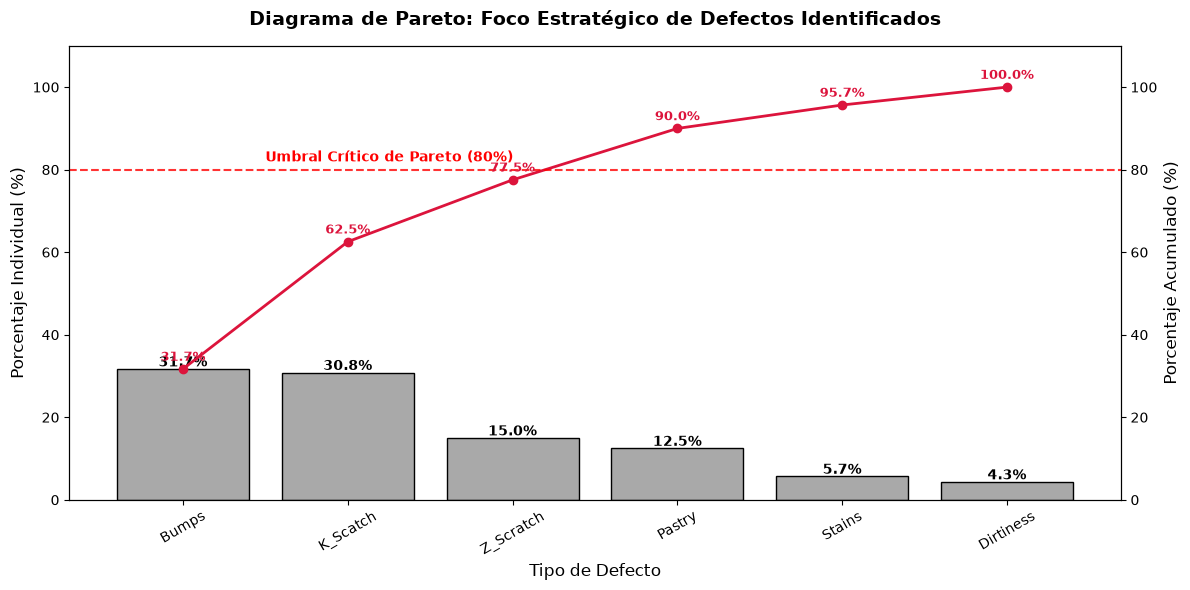

In [17]:
from utils.funciones import pareto_defectos
#Análisis de Pareto sin 'Other_Faults'
pareto_defectos(df)

Si limpiamos el dataset y dejamos fuera los errores no clasificados por el software, descubrimos el verdadero foco del problema: solo tres tipos de defectos (Bumps, K_Scatch y Z_Scratch) representan casi el 80% de todas las pérdidas por calidad de la planta (77.5%). Concentrar los esfuerzos de mantenimiento y calibración en estas tres áreas específicas erradicará de forma inmediata el grueso de las mermas en la producción de acero.

### 4.2 Análisis bivariante

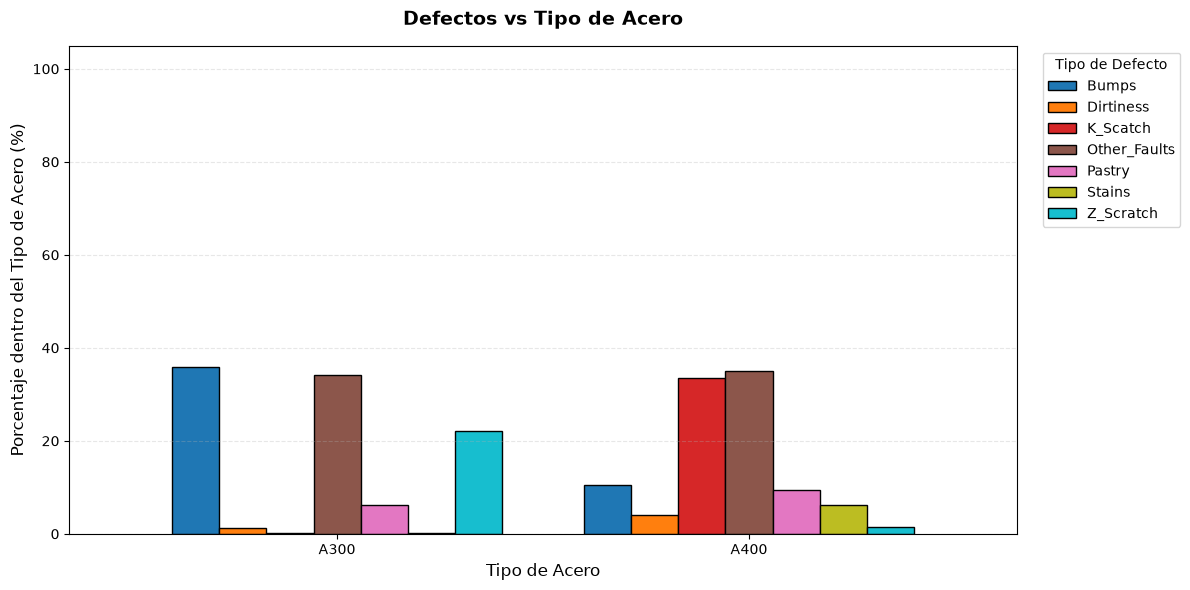

In [18]:
from utils.funciones import acero_vs_defecto
# Opción A: Barras separadas (Ideal para ver qué defecto sobresale en cada acero)
acero_vs_defecto(df, tipo_grafico='agrupado')

* En el gráfico anterior vimos que los Bumps y los K_Scratch acumulaban el grueso de los problemas identificados. Al cruzarlos con el tipo de acero, el dato nos da un diagnóstico quirúrgico: los Bumps son un problema exclusivo del acero blando A300, mientras que las rayas severas K_Scratch son una patología del acero duro A400.  
* • El acero A300 es una aleación físicamente más blanda o maleable. Por lo tanto, cuando pasa por la línea, cualquier variación de presión en los rodillos lo deforma fácilmente provocando abolladuras (Bumps). Las rayas que sufre son mayoritariamente superficiales y finas (Z_Scratch), causadas por roces ligeros. Prácticamente no tiene rayas severas (K_Scratch).  
* En el acero A400, el panorama cambia radicalmente. El defecto identificado que más sobresale son las rayas severas (K_Scatch, barra roja con ~34%). Además, es el único acero que presenta un porcentaje visible de manchas (Stains, barra verde oliva).  
* El porcentaje de fallos no clasificados (Other_Faults, barra marrón) se mantiene alto y casi idéntico en ambos aceros (~34% en A300 y ~35% en A400). Esto confirma que el problema de identificación del software de visión artificial es un defecto sistemático de calibración global. No depende del tipo de acero que se esté fabricando; las cámaras fallan por igual a la hora de etiquetar de manera unívoca un tercio de la producción en ambas aleaciones.

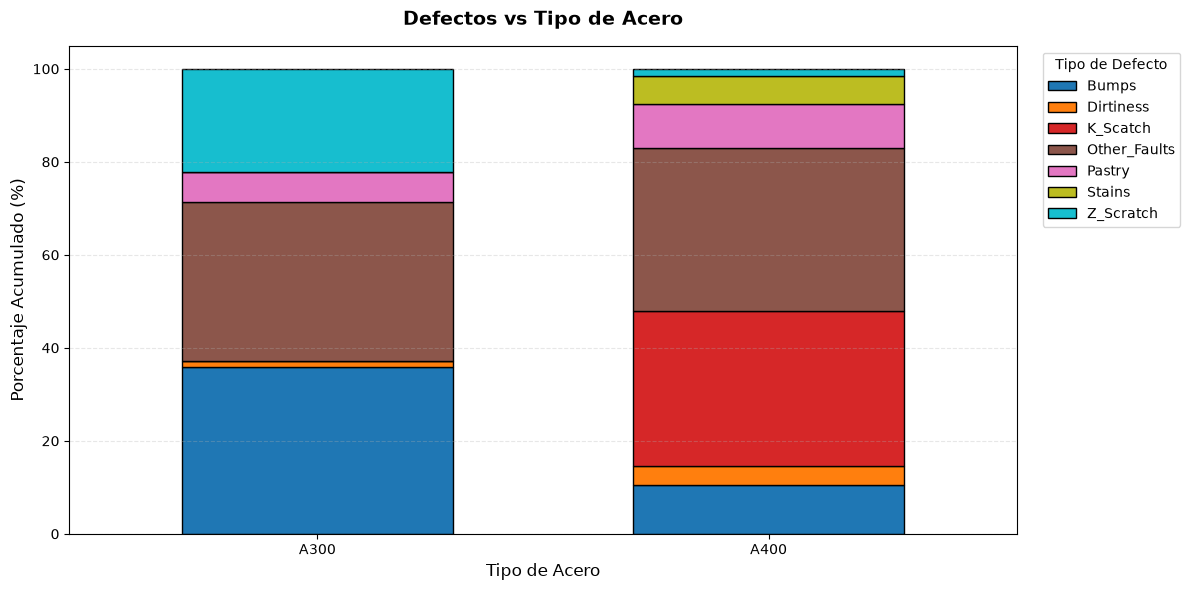

In [19]:
# Opción B: Barras apiladas (Ideal para comparar la composición total de fallas de un vistazo)
acero_vs_defecto(df, tipo_grafico='apilado')

Similar al anterior, otra representación

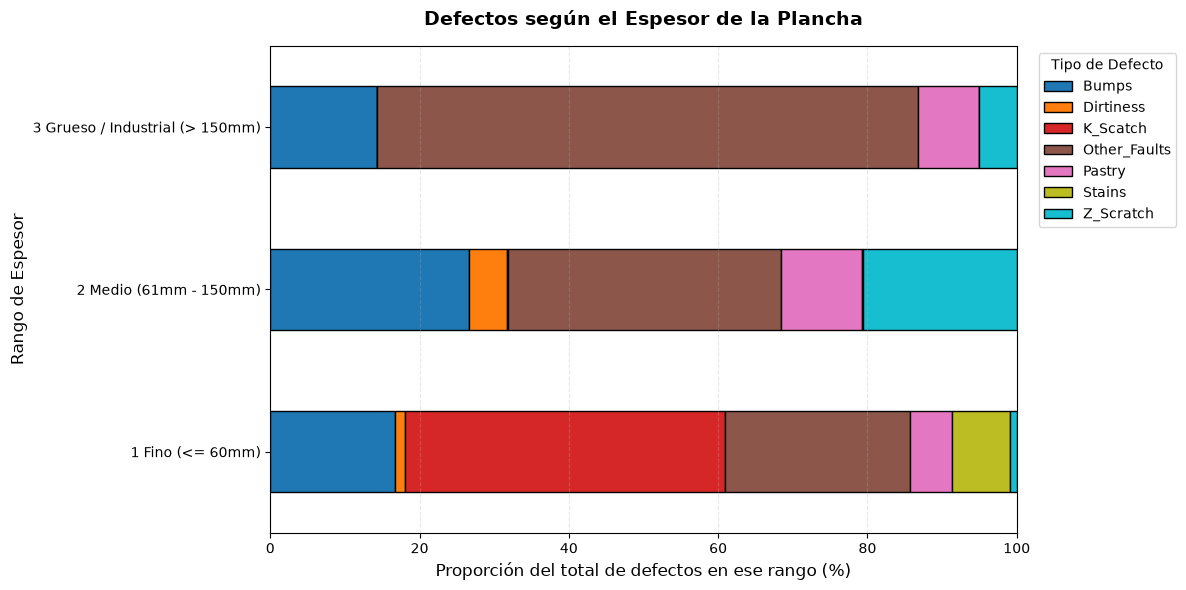

In [20]:
from utils.funciones import espesor_vs_defecto

espesor_vs_defecto(df)


* En las planchas finas, el defecto que devora la gráfica es K_Scatch (la gran franja roja que ocupa más del 40% del total de fallas de este rango). Además, aquí se concentran de manera casi exclusiva las manchas (Stains, franja verde oliva al final).  
* En el espesor medio, desaparecen por completo las rayas severas (K_Scratch), pero se disparan las abolladuras (Bumps, franja azul con ~27%) y las rayas finas o superficiales (Z_Scratch, franja cian con ~20%).  
* En los bloques gruesos industriales, el gráfico se tiñe casi por completo de marrón debido a Other_Faults, que representa más del 70% de todas las mermas de esta categoría. El resto son pequeños porcentajes de Bumps y pliegues (Pastry).  

### 4.3 Análisis multivariante

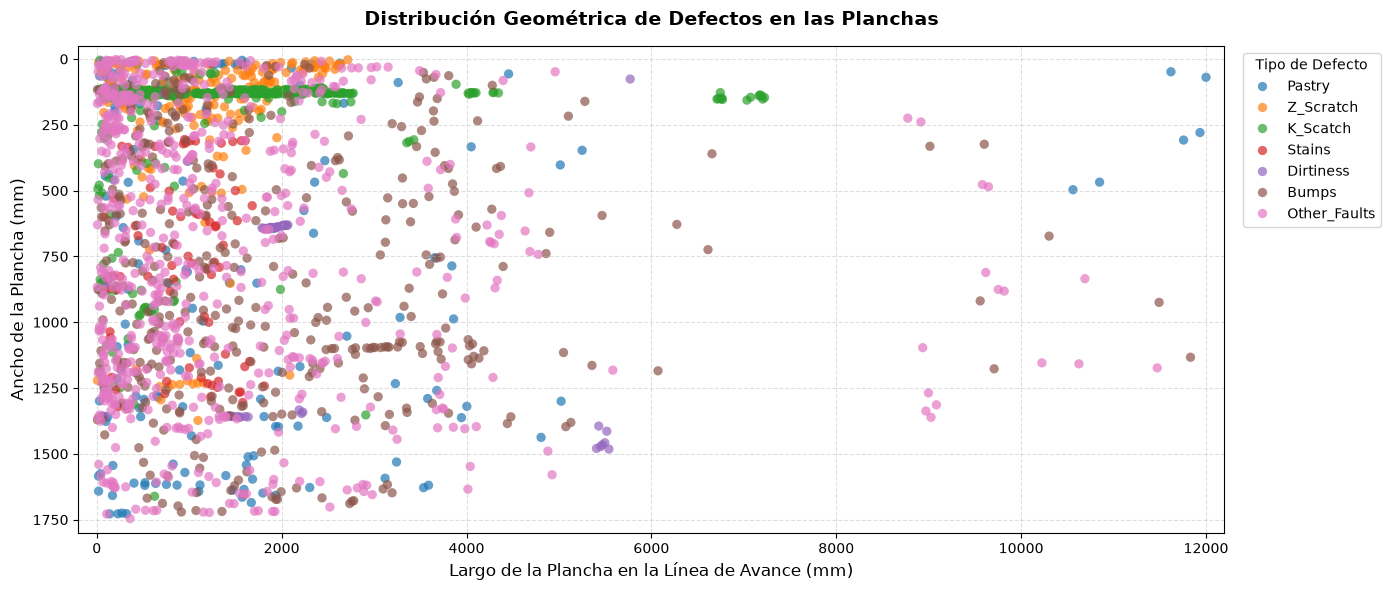

In [22]:
from utils.funciones import plot_plano_real_plancha

#Genero la simulación geométrica exacta de la línea de producción
plot_plano_real_plancha(df)

#Me quedo con este gráfico ya que es más representativo


* La línea verde horizontal perfecta que cruza de izquierda a derecha. Está situada exactamente a un ancho de Ancho ≈ 120 mm (cerca del borde superior de la plancha) y se extiende de forma continua a lo largo del proceso.Parece un fallo mecánico sistemático y fijo en la maquinaria.  
* Hay una densa y masiva acumulación de puntos de todos los colores en el extremo izquierdo del mapa, concentrada drásticamente entre los 0 y los 3.000 mm (primeros 3 metros) de largo de las planchas. Pasada esa frontera, la superficie se limpia de forma notable. Delata una severa inestabilidad en el impacto inicial o "cabeza" de la plancha. Cuando el desbaste (slab) de acero incandescente golpea por primera vez los rodillos de deformación, sufre los peores choques térmicos, pérdidas de tracción y desajustes de presión. Una vez que la máquina transforma los primeros 3 metros y el proceso se estabiliza, el acero empieza a salir limpio.  
* El defecto Pastry (solapamiento de metal) se concentra principalmente en la cabeza (primeros 2 metros) y se dispersa de forma aleatoria por el cuerpo de la plancha, compartiendo exactamente la misma distribución que los Bumps. Esto demuestra que es un fallo de origen metalúrgico heredado del desbaste (slab), donde las impurezas o burbujas internas del lingote original se abren y forman dobles capas debido a la enorme presión del proceso de laminación.
* Las rayas finas (Z_Scratch, naranja) y las manchas químicas (Stains, rojo oscuro) se agrupan casi al 100% pegadas a la banda de Ancho = 0. Esto indica problemas de rozamiento con los topes de centrado automático cuando la plancha entra ligeramente desviada por el lateral superior de la mesa de rodillos, acumulando también ahí los líquidos refrigerantes que causan las reacciones químicas en el acero duro.

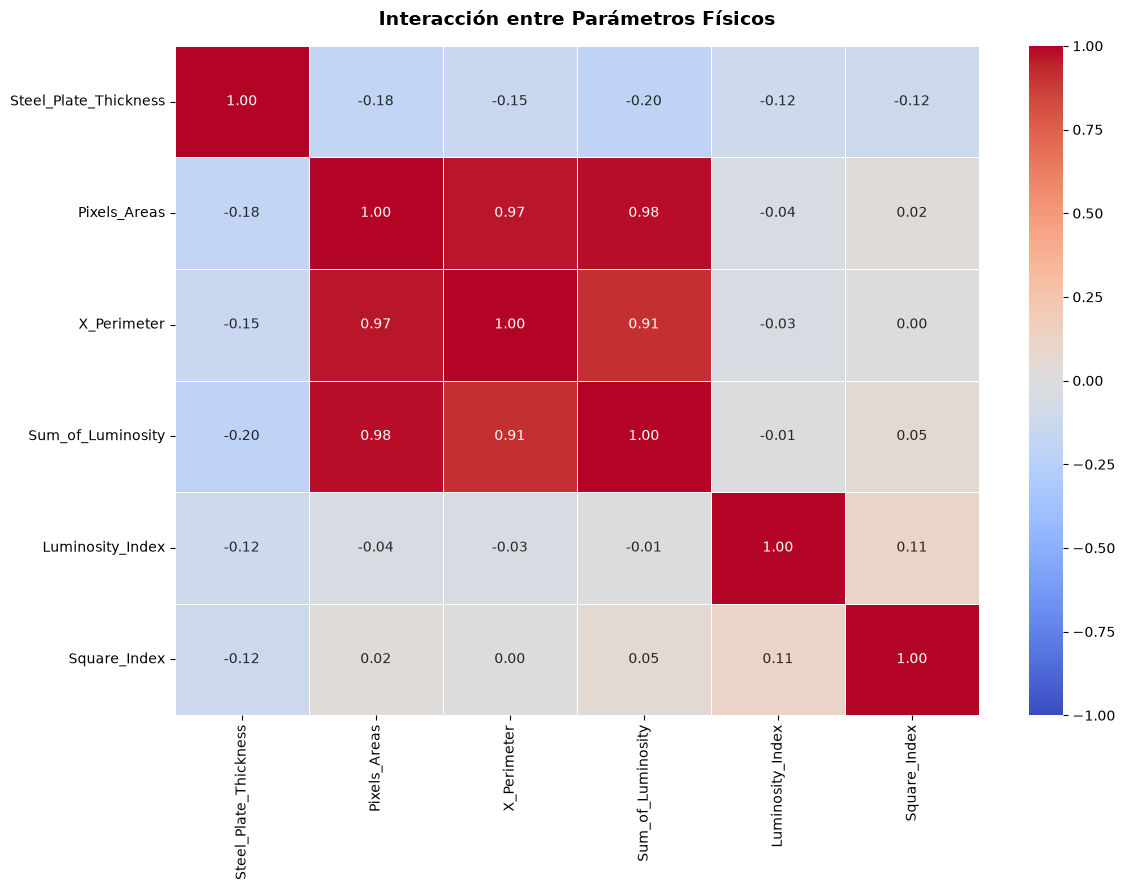

In [23]:
from utils.funciones import plot_multivariante_heatmap

# 1. Mapa de calor (Evaluamos magnitudes físicas e intensidades ópticas juntas)
columnas_interes = ['Steel_Plate_Thickness', 'Pixels_Areas', 'X_Perimeter', 
                     'Sum_of_Luminosity', 'Luminosity_Index', 'Square_Index']
plot_multivariante_heatmap(df, columnas_interes)

* Existe una correlación casi perfecta (entre 0.91 y 0.98) entre el tamaño del defecto (Pixels_Areas), su perímetro (X_Perimeter) y la luz total reflejada (Sum_of_Luminosity). Esto demuestra que el software calcula datos redundantes, lo que permite eliminar variables para aligerar la carga computacional de las cámaras sin perder precisión.  
* El grosor de la plancha (Steel_Plate_Thickness) tiene una correlación muy baja y negativa (entre -0.12 y -0.20) con el tamaño y brillo de las fallas. Esto confirma que el espesor influye en qué tipo de defecto aparece (visto en el bivariante), pero no condiciona la gravedad ni la magnitud física de la lesión una vez que se produce.  
* El índice de forma del fallo (Square_Index) muestra una correlación prácticamente nula (~0.00) con el resto de las variables. Esto prueba que la silueta o morfología de la imperfección es independiente de su tamaño o luminosidad; es decir, la forma geométrica viene determinada exclusivamente por el tipo de accidente mecánico que la causó (un roce genera una línea, un impacto genera un cuadrado) y no por la gravedad o magnitud de la falla.

## 5.Resultados